# Lesson 01 - Images as Arrays

**Part 1:** Classical 2D Image Processing (1960-1990)
**Source:** [https://sbirchfield.github.io/cvintro/lessons/lesson01_images_as_arrays.html](https://sbirchfield.github.io/cvintro/lessons/lesson01_images_as_arrays.html)
**Status:** in-progress

> One idea to remember: **an image is just a NumPy array**, so every array operation is an image operation.

## Goals
- [x] Represent grayscale and colour images as 2D / 3D arrays
- [x] Apply pixel-level operations and slicing
- [x] Understand the BGR (OpenCV) vs RGB (Matplotlib) trap

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

print("numpy", np.__version__, "| opencv", cv2.__version__)

numpy 1.26.4 | opencv 4.13.0


## 1. A grayscale image is a 2D array

Shape is `(height, width)`; each entry is an intensity in `0..255` (`uint8`).

[[  0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0]
 [  0   0 128 128 128 128   0   0]
 [  0   0 128 255 255 128   0   0]
 [  0   0 128 255 255 128   0   0]
 [  0   0 128 128 128 128   0   0]
 [  0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0]]
shape: (8, 8) dtype: uint8


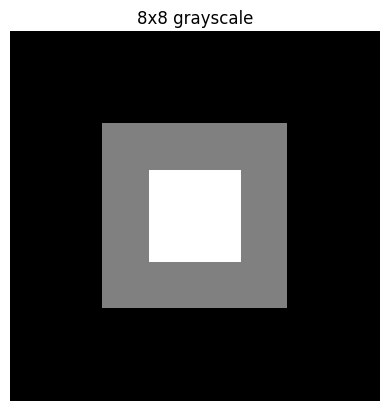

In [2]:
gray = np.zeros((8, 8), dtype=np.uint8)
gray[2:6, 2:6] = 128      # mid-gray square
gray[3:5, 3:5] = 255      # white core

print(gray)
print("shape:", gray.shape, "dtype:", gray.dtype)

plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("8x8 grayscale"); plt.axis("off"); plt.show()

**Note:** pass `vmin=0, vmax=255` - otherwise Matplotlib auto-stretches contrast and an
all-128 image looks white.

## 2. Pixel-level operations

Inversion is one array expression: `255 - img`.

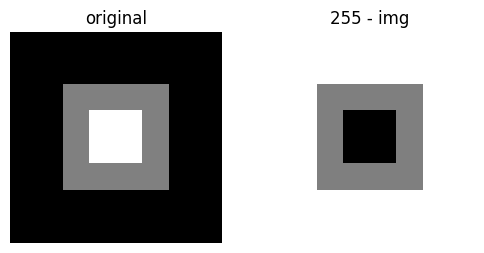

In [3]:
inverted = 255 - gray

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
for a, im, name in zip(ax, (gray, inverted), ("original", "255 - img")):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(name); a.axis("off")
plt.show()

## 3. A colour image is a 3D array

Shape `(height, width, channels)`. Below I build an image by hand, in **RGB** order.

shape: (100, 100, 3)


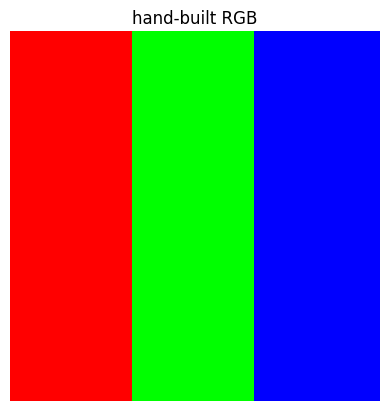

In [4]:
rgb = np.zeros((100, 100, 3), dtype=np.uint8)
rgb[:, :33, 0] = 255          # red band
rgb[:, 33:66, 1] = 255        # green band
rgb[:, 66:, 2] = 255          # blue band

print("shape:", rgb.shape)
plt.imshow(rgb); plt.title("hand-built RGB"); plt.axis("off"); plt.show()

## 4. Slicing = cropping, channel extraction

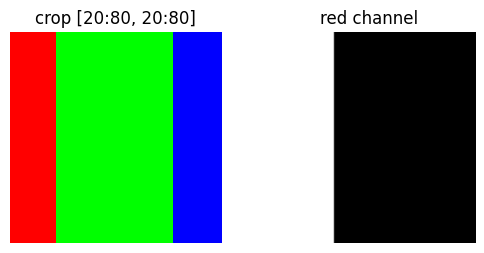

In [5]:
crop = rgb[20:80, 20:80]            # rows, cols
red_only = rgb[:, :, 0]            # one channel -> 2D

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(crop); ax[0].set_title("crop [20:80, 20:80]")
ax[1].imshow(red_only, cmap="gray"); ax[1].set_title("red channel")
for a in ax: a.axis("off")
plt.show()

## 5. The BGR vs RGB trap

`cv2.imread` returns channels in **BGR** order; `plt.imshow` expects **RGB**.
Showing an OpenCV image directly swaps red and blue.

Drop any photo at `data/sample.jpg` to use your own; otherwise a synthetic
"sunset" is generated so the notebook always runs.

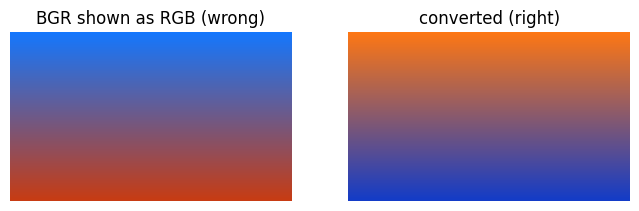

In [6]:
from pathlib import Path

sample = Path("../../data/sample.jpg")
img_bgr = cv2.imread(str(sample)) if sample.exists() else None

if img_bgr is None:                       # synthetic fallback: orange -> blue vertical gradient
    h, w = 120, 200
    t_ = np.linspace(0, 1, h)[:, None, None]
    top_rgb, bot_rgb = np.array([255, 120, 20]), np.array([20, 60, 200])
    img_rgb = ((1 - t_) * top_rgb + t_ * bot_rgb) * np.ones((1, w, 1))
    img_bgr = cv2.cvtColor(img_rgb.astype(np.uint8), cv2.COLOR_RGB2BGR)

wrong = img_bgr                                        # what beginners plot
right = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)       # or img_bgr[..., ::-1]

fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].imshow(wrong); ax[0].set_title("BGR shown as RGB (wrong)")
ax[1].imshow(right); ax[1].set_title("converted (right)")
for a in ax: a.axis("off")
plt.show()

## My own twist: verify the flip is just a reversed axis

`cvtColor(BGR2RGB)` and `[..., ::-1]` should be identical.

In [7]:
assert np.array_equal(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB), img_bgr[..., ::-1])
print("identical")

identical


## Takeaways
- Image = array; `shape`, `dtype`, and value range are the first things to check.
- Slicing gives crops and channels for free (views, not copies - `.copy()` before editing).
- Always convert BGR to RGB before Matplotlib.

## Where this shows up in real work
- Silent colour bugs when mixing OpenCV, PIL and PyTorch pipelines (BGR vs RGB, HWC vs CHW).
- Debugging data loaders: inspect `shape`/`dtype`/`min`/`max` first.